In [18]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

TRAIN_DIR = PROCESSED_DIR / "train"
STUDENT_TEST_DIR = PROCESSED_DIR / "student_test"

for path in [TRAIN_DIR, STUDENT_TEST_DIR]:
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}. Check that the cleaned data is inside "
            "PathSnap/data/processed/{train,student_test}."
        )

print("Project root:", PROJECT_ROOT)
print("Train directory:", TRAIN_DIR)
print("Student-test directory:", STUDENT_TEST_DIR)


Project root: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap
Train directory: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\data\processed\train
Student-test directory: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\data\processed\student_test


In [19]:
def find_trip_dirs(partition_dir):
    # A trip directory is expected to contain the four cleaned CSV files.
    required = {"track.csv", "nodes.csv", "arcs.csv", "route.csv"}
    trip_dirs = []
    for folder in sorted(p for p in partition_dir.iterdir() if p.is_dir()):
        if required.issubset({f.name for f in folder.iterdir() if f.is_file()}):
            trip_dirs.append(folder)
    return trip_dirs


def load_trip(folder):
    return {
        "track": pd.read_csv(folder / "track.csv"),
        "nodes": pd.read_csv(folder / "nodes.csv"),
        "arcs": pd.read_csv(folder / "arcs.csv"),
        "route": pd.read_csv(folder / "route.csv"),
    }


train_dirs = find_trip_dirs(TRAIN_DIR)
test_dirs = find_trip_dirs(STUDENT_TEST_DIR)

print(f"Train trips found: {len(train_dirs)}")
print(f"Student-test trips found: {len(test_dirs)}")

if not train_dirs:
    raise RuntimeError("No train trip folders found. Check the folder structure and CSV names.")


Train trips found: 80
Student-test trips found: 10


In [20]:
sample = load_trip(train_dirs[0])

for name, frame in sample.items():
    print(f"\\n--- {name.upper()} ---")
    print("Shape:", frame.shape)
    print("Columns:", frame.columns.tolist())
    display(frame.head())
    print(frame.dtypes)


\n--- TRACK ---
Shape: (1315, 4)
Columns: ['observation_id', 'longitude', 'latitude', 'timestamp_s']


,observation_id,longitude,latitude,timestamp_s
0,0,8.595203,49.844053,1.0
1,1,8.595294,49.844441,2.0
2,2,8.595352,49.844883,3.0
3,3,8.595390,49.845379,4.0
4,4,8.595587,49.845750,5.0


observation_id      int64
longitude         float64
latitude          float64
timestamp_s       float64
dtype: object
\n--- NODES ---
Shape: (88809, 3)
Columns: ['node_id', 'longitude', 'latitude']


,node_id,longitude,latitude
0,0,8.581679,49.857880
1,1,8.584637,49.858295
2,2,8.580173,49.858567
3,3,8.584392,49.859119
4,4,8.584935,49.857396


node_id        int64
longitude    float64
latitude     float64
dtype: object
\n--- ARCS ---
Shape: (165790, 3)
Columns: ['arc_id', 'from_node_id', 'to_node_id']


,arc_id,from_node_id,to_node_id
0,0,0,281
1,1,0,1
2,2,0,5
3,3,1,0
4,4,1,40750


arc_id          int64
from_node_id    int64
to_node_id      int64
dtype: object
\n--- ROUTE ---
Shape: (525, 2)
Columns: ['route_step', 'arc_id']


,route_step,arc_id
0,0,2641
1,1,64973
2,2,133948
3,3,133949
4,4,139208


route_step    int64
arc_id        int64
dtype: object


In [21]:
def partition_inventory(trip_dirs, partition_name):
    rows = []
    for folder in trip_dirs:
        data = load_trip(folder)
        rows.append({
            "partition": partition_name,
            "trip_id": folder.name,
            "gps_observations": len(data["track"]),
            "road_nodes": len(data["nodes"]),
            "road_arcs": len(data["arcs"]),
            "reference_route_steps": len(data["route"]),
        })
    return pd.DataFrame(rows)


train_inventory = partition_inventory(train_dirs, "train")
test_inventory = partition_inventory(test_dirs, "student_test")
inventory = pd.concat([train_inventory, test_inventory], ignore_index=True)

display(inventory.describe(include="all"))
display(inventory)


,partition,trip_id,gps_observations,road_nodes,road_arcs,reference_route_steps
count,90,90,90.000000,90.000000,90.000000,90.000000
unique,2,90,NaN,NaN,NaN,NaN
top,train,00000001,NaN,NaN,NaN,NaN
freq,80,1,NaN,NaN,NaN,NaN
mean,NaN,NaN,2528.633333,22490.822222,45132.722222,386.811111
std,NaN,NaN,3156.999879,30868.526339,61920.284604,359.238455
min,NaN,NaN,262.000000,299.000000,649.000000,59.000000
25%,NaN,NaN,899.250000,3655.250000,7282.750000,166.750000
50%,NaN,NaN,1496.500000,9305.000000,18761.500000,272.500000
75%,NaN,NaN,2816.250000,26296.500000,52913.250000,464.250000


,partition,trip_id,gps_observations,road_nodes,road_arcs,reference_route_steps
0,train,00000001,1315,88809,165790,525
1,train,00000002,7243,7936,16139,262
2,train,00000003,821,9138,18028,79
3,train,00000004,1064,7350,15499,320
4,train,00000005,1045,898,1579,105
...,...,...,...,...,...,...
85,student_test,00000056,3958,14759,27631,1323
86,student_test,00000065,768,6448,13184,145
87,student_test,00000076,1486,26635,56027,374
88,student_test,00000077,3911,4424,9622,268


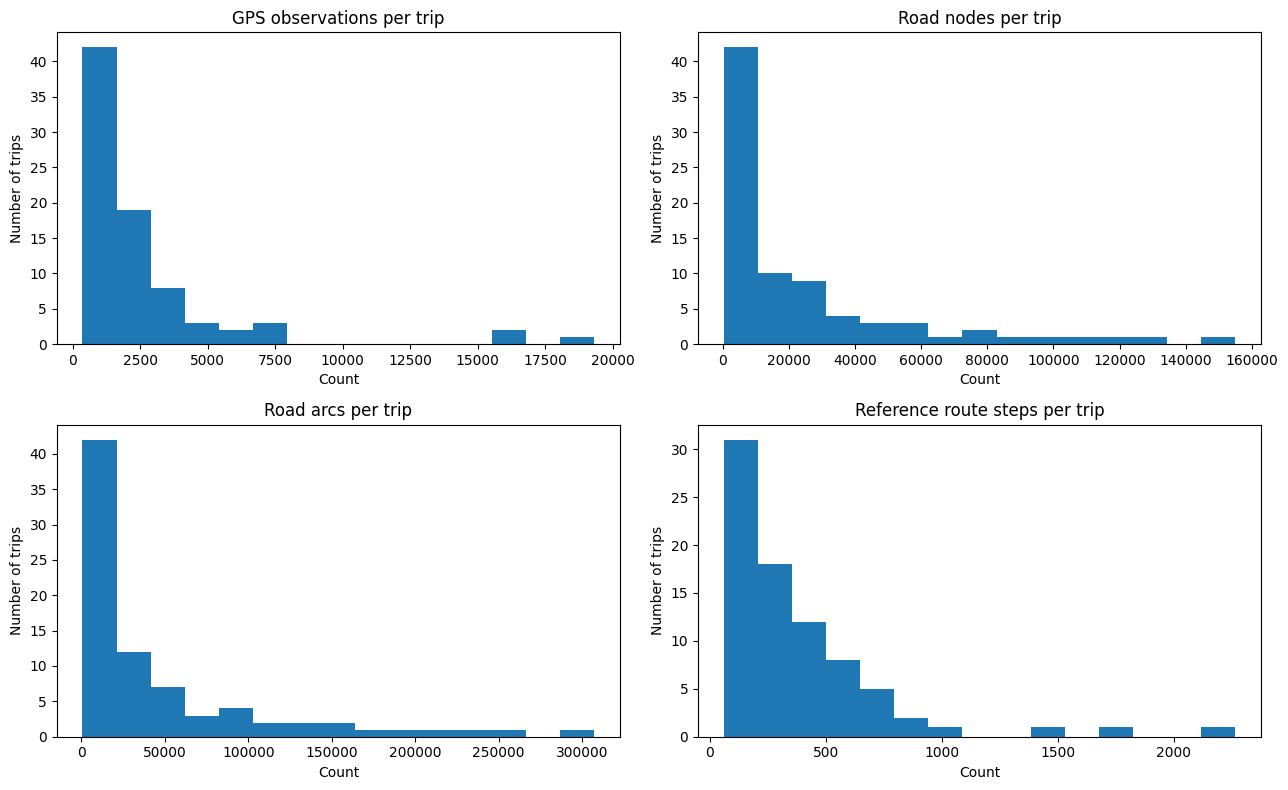

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metrics = [
    ("gps_observations", "GPS observations per trip"),
    ("road_nodes", "Road nodes per trip"),
    ("road_arcs", "Road arcs per trip"),
    ("reference_route_steps", "Reference route steps per trip"),
]
for ax, (column, title) in zip(axes.flat, metrics):
    ax.hist(train_inventory[column], bins=15)
    ax.set_title(title)
    ax.set_xlabel("Count")
    ax.set_ylabel("Number of trips")
plt.tight_layout()
plt.show()


Number of consecutive intervals: 208337
count    208337.000000
mean          2.181237
std         354.852204
min           1.000000
50%           1.000000
90%           1.000000
95%           1.000000
99%           3.000000
max      153064.000000
Name: delta_seconds, dtype: float64
Non-positive intervals: 0


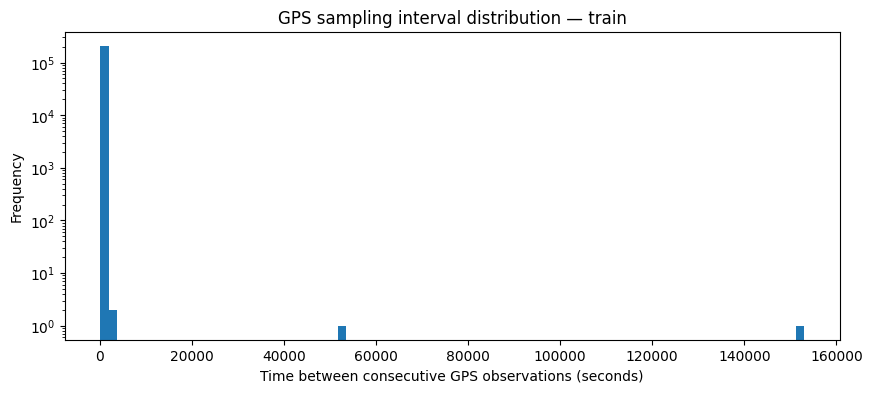

In [23]:
def get_timestamp_column(track):
    candidates = ["timestamp_s", "timestamp", "time", "datetime", "t"]
    for col in candidates:
        if col in track.columns:
            return col
    raise KeyError(f"No recognised timestamp column. Found: {track.columns.tolist()}")


def timestamp_deltas(track):
    col = get_timestamp_column(track)
    values = track[col]
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().all():
        times = numeric.to_numpy(dtype=float)
    else:
        parsed = pd.to_datetime(values, errors="coerce", utc=True)
        if parsed.isna().any():
            raise ValueError(f"Could not parse every value in timestamp column {col!r}")
        times = parsed.astype("int64").to_numpy(dtype=float) / 1e9
    return np.diff(times)


all_deltas = []
for folder in train_dirs:
    track = load_trip(folder)["track"]
    if len(track) > 1:
        all_deltas.extend(timestamp_deltas(track))

all_deltas = np.asarray(all_deltas, dtype=float)
all_deltas = all_deltas[np.isfinite(all_deltas)]

print("Number of consecutive intervals:", len(all_deltas))
print(pd.Series(all_deltas, name="delta_seconds").describe(percentiles=[.5, .9, .95, .99]))
print("Non-positive intervals:", int((all_deltas <= 0).sum()))

plt.figure(figsize=(10, 4))
plt.hist(all_deltas[all_deltas > 0], bins=80)
plt.xlabel("Time between consecutive GPS observations (seconds)")
plt.ylabel("Frequency")
plt.title("GPS sampling interval distribution — train")
plt.yscale("log")
plt.show()


In [24]:
def coordinate_columns(frame):
    pairs = [
        ("longitude", "latitude"),
        ("lon", "lat"),
        ("lng", "lat"),
        ("x", "y"),
    ]
    for x_col, y_col in pairs:
        if x_col in frame.columns and y_col in frame.columns:
            return x_col, y_col
    raise KeyError(f"Could not identify coordinate columns in {frame.columns.tolist()}")


coordinate_rows = []
for folder in train_dirs:
    track = load_trip(folder)["track"]
    x_col, y_col = coordinate_columns(track)
    coordinate_rows.append({
        "trip_id": folder.name,
        "min_longitude": track[x_col].min(),
        "max_longitude": track[x_col].max(),
        "min_latitude": track[y_col].min(),
        "max_latitude": track[y_col].max(),
    })

coordinate_summary = pd.DataFrame(coordinate_rows)
display(coordinate_summary.describe())


,min_longitude,max_longitude,min_latitude,max_latitude
count,80.000000,80.000000,80.000000,80.000000
mean,15.562430,15.749707,44.311396,44.419168
std,47.966493,47.975984,18.381581,18.372341
min,-100.418538,-100.268049,-34.640291,-34.609083
25%,-1.350866,-1.319847,41.419023,41.453002
50%,12.526349,12.729876,50.101096,50.206652
75%,37.400413,37.456494,53.841667,53.873337
max,137.197657,137.237029,61.233324,61.267258


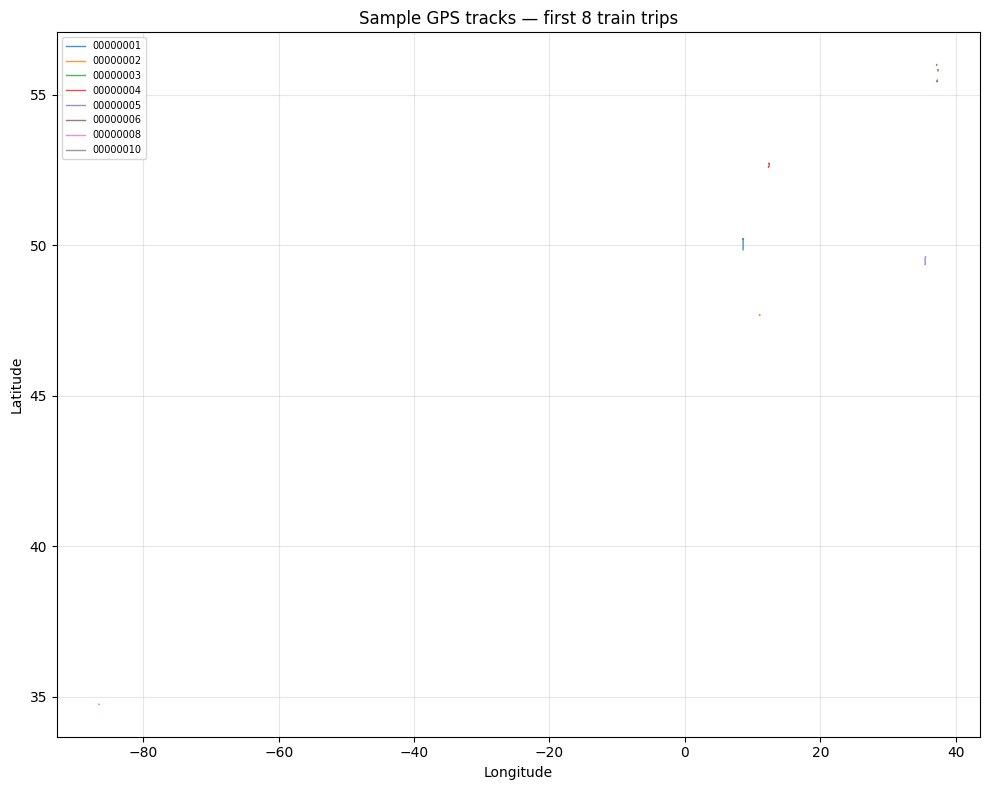

In [25]:
n_to_plot = min(8, len(train_dirs))
fig, ax = plt.subplots(figsize=(10, 8))

for folder in train_dirs[:n_to_plot]:
    track = load_trip(folder)["track"]
    x_col, y_col = coordinate_columns(track)
    ax.plot(track[x_col], track[y_col], linewidth=1, alpha=0.8, label=folder.name)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Sample GPS tracks — first {n_to_plot} train trips")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [26]:
def graph_checks(data):
    nodes, arcs = data["nodes"], data["arcs"]
    possible_from = ["from_node_id", "from", "source", "u"]
    possible_to = ["to_node_id", "to", "target", "v"]
    from_col = next((c for c in possible_from if c in arcs.columns), None)
    to_col = next((c for c in possible_to if c in arcs.columns), None)
    if from_col is None or to_col is None:
        raise KeyError(f"Could not identify arc endpoint columns: {arcs.columns.tolist()}")

    src = pd.to_numeric(arcs[from_col], errors="coerce")
    dst = pd.to_numeric(arcs[to_col], errors="coerce")
    valid_src = src.notna() & src.between(0, len(nodes) - 1)
    valid_dst = dst.notna() & dst.between(0, len(nodes) - 1)

    out_degree = src[valid_src].astype(int).value_counts()
    in_degree = dst[valid_dst].astype(int).value_counts()

    return {
        "node_count": len(nodes),
        "arc_count": len(arcs),
        "invalid_from_refs": int((~valid_src).sum()),
        "invalid_to_refs": int((~valid_dst).sum()),
        "mean_out_degree_nonzero": float(out_degree.mean()) if len(out_degree) else 0.0,
        "mean_in_degree_nonzero": float(in_degree.mean()) if len(in_degree) else 0.0,
        "max_out_degree": int(out_degree.max()) if len(out_degree) else 0,
        "max_in_degree": int(in_degree.max()) if len(in_degree) else 0,
    }


graph_summary = []
for folder in train_dirs:
    result = graph_checks(load_trip(folder))
    result["trip_id"] = folder.name
    graph_summary.append(result)

graph_summary = pd.DataFrame(graph_summary)
display(graph_summary.describe(include="all"))
print("Total invalid endpoint references:",
      graph_summary[["invalid_from_refs", "invalid_to_refs"]].to_numpy().sum())


,node_count,arc_count,invalid_from_refs,invalid_to_refs,mean_out_degree_nonzero,mean_in_degree_nonzero,max_out_degree,max_in_degree,trip_id
count,80.000000,80.00000,80.0,80.0,80.000000,80.000000,80.000000,80.00000,80
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00000001
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
mean,24168.562500,48461.30000,0.0,0.0,2.023750,2.023768,5.250000,5.16250,NaN
std,32272.296272,64738.83689,0.0,0.0,0.129382,0.129383,0.961276,0.90629,NaN
min,299.000000,649.00000,0.0,0.0,1.670557,1.671191,4.000000,4.00000,NaN
25%,3487.750000,7061.75000,0.0,0.0,1.971249,1.971287,5.000000,5.00000,NaN
50%,9608.000000,19526.50000,0.0,0.0,2.030417,2.030511,5.000000,5.00000,NaN
75%,28846.750000,58003.25000,0.0,0.0,2.093188,2.093196,6.000000,6.00000,NaN


Total invalid endpoint references: 0


,route_steps,valid_route_arc_ids,invalid_route_arc_ids,gps_observations,route_steps_per_gps_observation
count,80.000000,80.000000,80.0,80.000000,80.000000
mean,391.700000,391.700000,0.0,2605.212500,0.226142
std,361.165497,361.165497,0.0,3312.345399,0.157177
min,59.000000,59.000000,0.0,361.000000,0.017551
25%,168.250000,168.250000,0.0,945.750000,0.118630
50%,280.000000,280.000000,0.0,1529.000000,0.189113
75%,480.500000,480.500000,0.0,2792.750000,0.301529
max,2266.000000,2266.000000,0.0,19313.000000,0.793249


Invalid route arc references: 0


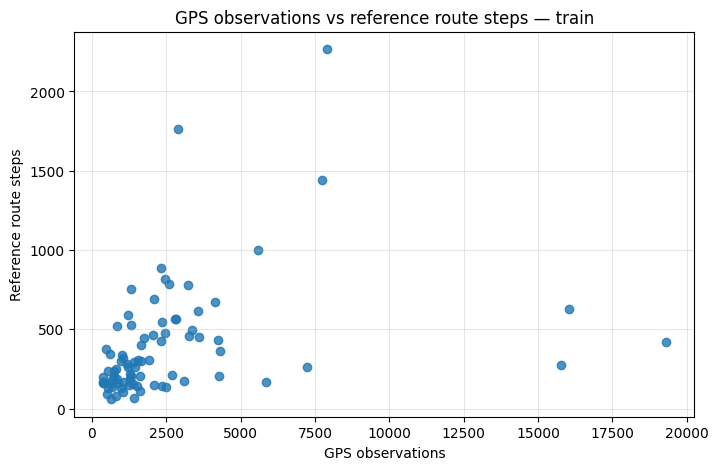

In [27]:
def route_arc_column(route):
    candidates = ["arc_id", "arc", "edge_id", "id"]
    for col in candidates:
        if col in route.columns:
            return col
    if route.shape[1] == 1:
        return route.columns[0]
    raise KeyError(f"Could not identify route arc-ID column: {route.columns.tolist()}")


route_rows = []
for folder in train_dirs:
    data = load_trip(folder)
    col = route_arc_column(data["route"])
    arc_ids = pd.to_numeric(data["route"][col], errors="coerce")
    valid = arc_ids.notna() & arc_ids.between(0, len(data["arcs"]) - 1)
    route_rows.append({
        "trip_id": folder.name,
        "route_steps": len(data["route"]),
        "valid_route_arc_ids": int(valid.sum()),
        "invalid_route_arc_ids": int((~valid).sum()),
        "gps_observations": len(data["track"]),
        "route_steps_per_gps_observation": len(data["route"]) / max(len(data["track"]), 1),
    })

route_summary = pd.DataFrame(route_rows)
display(route_summary.describe())
print("Invalid route arc references:", route_summary["invalid_route_arc_ids"].sum())

plt.figure(figsize=(8, 5))
plt.scatter(route_summary["gps_observations"], route_summary["route_steps"], alpha=0.8)
plt.xlabel("GPS observations")
plt.ylabel("Reference route steps")
plt.title("GPS observations vs reference route steps — train")
plt.grid(True, alpha=0.3)
plt.show()


In [28]:
comparison = inventory.groupby("partition")[[
    "gps_observations", "road_nodes", "road_arcs", "reference_route_steps"
]].agg(["count", "mean", "median", "min", "max"])

display(comparison)


gps_observations                                road_nodes  \
                        count       mean  median  min    max      count   
partition                                                                 
student_test               10  1916.0000  1420.0  262   3958         10   
train                      80  2605.2125  1529.0  361  19313         80   

                                               road_arcs                    \
                    mean  median   min     max     count     mean   median   
partition                                                                    
student_test   9068.9000  6596.5  1770   26635        10  18504.1  13145.0   
train         24168.5625  9608.0   299  155003        80  48461.3  19526.5   

                           reference_route_steps                          
               min     max                 count   mean median min   max  
partition                                                                 
student_test  3577   56027                    10  347.7  250.0  95  1323  
train          649  307392                    80  391.7  280.0  59  2266

In [29]:
EDA_DIR = PROJECT_ROOT / "experiments" / "results" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

inventory.to_csv(EDA_DIR / "trip_inventory.csv", index=False)
coordinate_summary.to_csv(EDA_DIR / "train_coordinate_summary.csv", index=False)
graph_summary.to_csv(EDA_DIR / "train_graph_summary.csv", index=False)
route_summary.to_csv(EDA_DIR / "train_route_summary.csv", index=False)

print("Saved EDA summaries to:", EDA_DIR)


Saved EDA summaries to: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\experiments\results\eda


## 9. What we need to learn before candidate generation

After running this notebook, record:

1. Typical and extreme GPS sampling intervals.
2. Whether trips have very large time gaps.
3. The distribution of GPS observations, nodes, arcs, and route steps.
4. Whether graph endpoint and route arc references remain valid.
5. Whether train and student-test distributions look broadly comparable.
6. Any unusual tracks or trips that deserve closer inspection.

**Do not start candidate generation until we have reviewed these outputs.** Candidate search radius, temporal handling, and spatial indexing should be informed by the observed data.
